# Camera Stabilizer Network

### Contents

+ Imports
+ Data import
+ Data preprocessing (rotation generation)
+ Model and head constructions
+ Models (train set) evaluation
+ Final training with top contendors


In [ ]:
import os
from PIL import Image
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt 
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, models
from torchvision.transforms import Compose
import cv2
from itertools import chain



## Data annotation
Here we showcase what the data looks like and what we have to work with when training our model

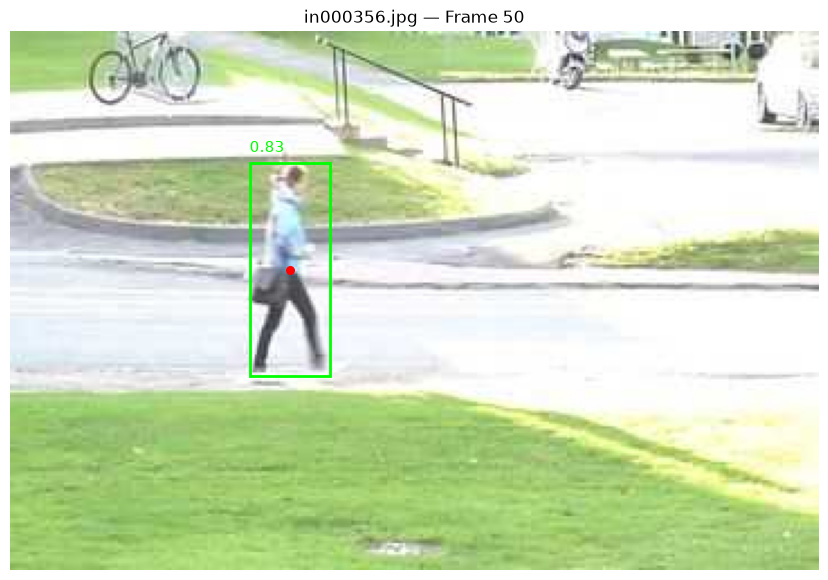

In [236]:
# Select video and frame
video_dir = Path("dataset/singleObjectDetection/train/Person1")
frame_idx = 50

# Load image
image_paths = sorted((video_dir / "input").glob("*.jpg"))
image_path = image_paths[frame_idx]
image = cv2.cvtColor(cv2.imread(str(image_path)), cv2.COLOR_BGR2RGB)

# Load saved bounding boxes
df = pd.read_csv(video_dir / "positions.csv")
detections = df[df["filename"] == image_path.name]

# Display image
fig, ax = plt.subplots(figsize=(12, 7))
ax.imshow(image)

for _, box in detections.iterrows():

    # Bounding box
    rect = patches.Rectangle(
        (box["x1"], box["y1"]),
        box["x2"] - box["x1"],
        box["y2"] - box["y1"],
        linewidth=2,
        edgecolor="lime",
        facecolor="none"
    )
    ax.add_patch(rect)

    # Tracking position
    ax.scatter(box["cx"], box["cy"], color="red", s=30)

    # Detection confidence
    ax.text(
        box["x1"], box["y1"] - 5,
        f'{box["confidence"]:.2f}',
        color="lime",
        fontsize=11
    )

ax.set_title(f"{image_path.name} — Frame {frame_idx}")
ax.axis("off")
plt.show()

In [230]:
data_root = (Path.cwd() / "data" / "train").resolve()

train_path = data_root / "train"
val_path = data_root / "val"
small_train_path = data_root / "small-train"
small_val_path = data_root / "small-val"


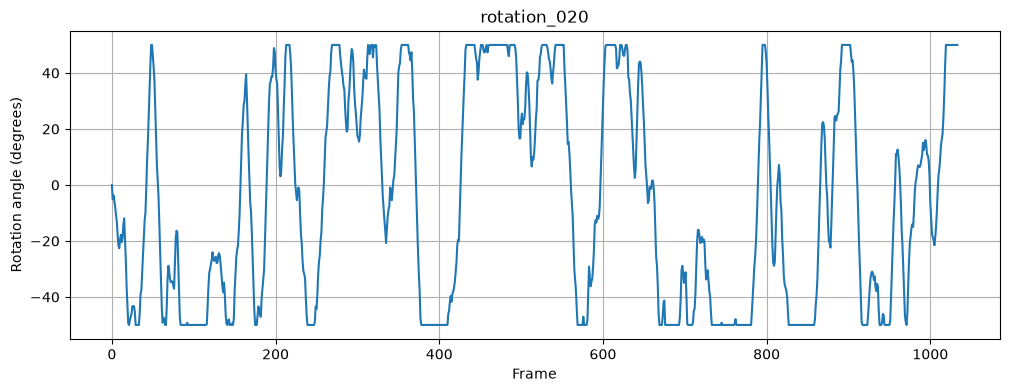

In [226]:
csv_path = Path("dataset/singleObjectDetection/test/Boat2/rotation_labels/rotation_020.csv")

# Load rotation trajectory
df = pd.read_csv(csv_path)

# Plot
plt.figure(figsize=(12, 4))
plt.plot(df.index, df["angle_deg"])

plt.xlabel("Frame")
plt.ylabel("Rotation angle (degrees)")
plt.title(csv_path.stem)
plt.grid(True)
plt.show()

## Dataset Structure

The CDnet (Change detection net) dataset contains 11 video categories with 4 to 6 videos in each category. This project chooses 3 videos with obtimal conditions for object detection with good weather conditions, small amount of shadows 

In [237]:
root = Path("dataset/singleObjectDetection")


In [ ]:
class RotationPositionDataset(Dataset):

    def __init__(
        self,
        split_dir,
        position_file="positions.csv",
        max_side=128,
        transform=None
    ):
        self.csv_files = sorted(
            Path(split_dir).glob("*/rotation_labels/rotation_*.csv")
        )

        self.position_file = position_file
        self.max_side = max_side
        self.transform = transform

    def __len__(self):
        return len(self.csv_files)

    def __getitem__(self, idx):

        csv_path = self.csv_files[idx]
        video_dir = csv_path.parent.parent

        rotations = pd.read_csv(csv_path)

        # Match object positions to rotation labels by filename
        positions = (
            pd.read_csv(video_dir / self.position_file)
            .set_index("filename")
            .reindex(rotations["filename"])
        )

        xy = positions[["cx", "cy"]].to_numpy(dtype=np.float32)

        images = []
        original_xy = []
        rotated_xy = []
        valid = []

        for i, row in enumerate(rotations.itertuples(index=False)):

            image = cv2.imread(str(video_dir / "input" / row.filename))
            h, w = image.shape[:2]

            M = cv2.getRotationMatrix2D(
                (w / 2, h / 2),
                row.angle_deg,
                row.zoom
            )

            # Rotate image
            image = cv2.warpAffine(image, M, (w, h))

            # Rotate object position using the same matrix
            point = xy[i]
            point_rot = M @ np.array([point[0], point[1], 1.0])

            # Normalize positions to image coordinates [0,1]
            original_xy.append(point / [w, h])
            rotated_xy.append(point_rot / [w, h])

            valid.append(
                np.isfinite(point_rot).all()
                and 0 <= point_rot[0] < w
                and 0 <= point_rot[1] < h
            )

            # Resize image
            scale = self.max_side / max(h, w)
            new_size = (
                max(8, round(w * scale / 8) * 8),
                max(8, round(h * scale / 8) * 8)
            )

            image = cv2.resize(image, new_size)
            images.append(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))

        frames = torch.from_numpy(
            np.stack(images)
        ).permute(0, 3, 1, 2).float() / 255.0

        return {
            "frames": frames,
            "angles": torch.tensor(
                rotations["angle_deg"].to_numpy(), dtype=torch.float32
            ),
            "pos_original": torch.tensor(original_xy, dtype=torch.float32),
            "pos_rotated": torch.tensor(rotated_xy, dtype=torch.float32),
            "pos_valid": torch.tensor(valid, dtype=torch.bool),
            "zoom": torch.tensor(
                rotations["zoom"].to_numpy(), dtype=torch.float32
            )
        }

In [ ]:

train_transform = transforms.Compose([
    transforms.ColorJitter(
        brightness=0.15,
        contrast=0.15,
        saturation=0.10
    ),

    transforms.RandomApply(
        [transforms.GaussianBlur(kernel_size=3, sigma=(0.1, 0.7))],
        p=0.15
    )
])

val_transform = None
test_transform = None

In [ ]:

train_loader = DataLoader(
    RotationPositionDataset(root / "train", "person_positions.csv"),
    batch_size=1,
    shuffle=True
)

val_loader = DataLoader(
    RotationPositionDataset(root / "val", "person_positions.csv"),
    batch_size=1,
    shuffle=False
)

test_loader = DataLoader(
    RotationPositionDataset(root / "test", "person_positions.csv"),
    batch_size=1,
    shuffle=False
)